In [ ]:
import matplotlib.pyplot as plt
import torch
import math

def get_ndc_range(pixels):
    half_pixels = pixels / 2
    pixel_space = torch.arange(start=0, end=pixels, step=1.0) + 0.5
    ndc_space = (pixel_space - half_pixels) / half_pixels
    return ndc_space

def ndc_pixel_coordinates(width, height):
    x = get_ndc_range(width)
    y = get_ndc_range(height)
    yy, xx = torch.meshgrid(x, y, indexing='ij')
    ndc_grid = torch.stack((xx, yy), dim=-1)
    return ndc_grid

def z_sort_gaussians(means, covariances, colors, opacities):
    sorted_indices = torch.argsort(means[:, 2])
    sorted_means = means[sorted_indices]
    sorted_covariances = covariances[sorted_indices]
    sorted_colors = colors[sorted_indices]
    sorted_opacities = opacities[sorted_indices]
    return sorted_means, sorted_covariances, sorted_colors, sorted_opacities

def render_alpha_blend(width, height, means, covariances, colors, opacities):
    means, covariances, colors, opacities = z_sort_gaussians(means, covariances, colors, opacities)
    ndc_grid = ndc_pixel_coordinates(width, height) # [H, W, 2]
    img = torch.zeros((3, width, height), device=means.device) # [C, H, W]
    T = torch.ones((1, width, height), device=means.device) # [1, H, W]

    for mean, cov, color, opacity in zip(means, covariances, colors, opacities):
        xy_mean = mean[:2]
        d = (ndc_grid - xy_mean[None, None, ...])
        alpha = opacity[None, None, ...] * torch.exp(-0.5 * torch.sum(d @ torch.linalg.inv(cov) * d, dim=-1))
        img += T * alpha * color[..., None, None]
        T *= (1 - alpha)

    return img



In [26]:
def world2view_from_rotation_translation(rotation, translation):
    R = torch.as_tensor(rotation, dtype=torch.float32)
    t = torch.as_tensor(translation, dtype=torch.float32)
    world2view = torch.eye(4, dtype=torch.float32)
    world2view[:3, :3] = R
    world2view[:3, 3] = t
    return world2view

def get_projection_matrix(fovx, fovy, znear=0.01, zfar=100.0):
    fovx_rad = math.radians(fovx)
    fovy_rad = math.radians(fovy)
    fx = 1 / math.tan(fovx_rad / 2)
    fy = 1 / math.tan(fovy_rad / 2)

    projection_matrix = torch.zeros((4, 4), dtype=torch.float32)
    projection_matrix[0, 0] = fx
    projection_matrix[1, 1] = fy
    projection_matrix[2, 2] = zfar / (zfar - znear)
    projection_matrix[2, 3] = -(zfar * znear) / (zfar - znear)
    projection_matrix[3, 2] = 1.0
    return projection_matrix

def geom_transform_points(points, transf_matrix):
    num_points = points.shape[0]
    ones = torch.ones((num_points, 1), device=points.device, dtype=points.dtype)
    points_hom = torch.cat([points, ones], dim=-1)  # [N, 4]
    points_out = (transf_matrix @ points_hom.T).T  # [N, 4]

    denom = points_out[..., 3:] + 1e-8
    return (points_out[..., :3] / denom).squeeze(dim=0)

class Camera:
    def __init__(
        self,
        rotation: torch.Tensor,
        translation: torch.Tensor,
        width: int,
        height: int,
        fovy: int,
        fovx: float,
        device: str = "cpu",
    ):
        self.width = width
        self.height = height
        self.fovy = fovy
        self.fovx = fovx

        self.proj_mat = get_projection_matrix(fovx, fovy).to(device)

        self.world_view_transform = world2view_from_rotation_translation(rotation, translation).to(device)

    def project_points(self, points):
        projected_points = geom_transform_points(points, self.proj_mat @ self.world_view_transform)
        return projected_points

In [ ]:
def compute_jacobians(means, camera):
    t = geom_transform_points(means, camera.world_view_transform)
    l = t.norm(dim=1, keepdim=True).flatten()

    jacobian = torch.zeros(t.shape[0], 3, 3)
    jacobian[:, 0, 0] = 1 / t[:, 2]
    jacobian[:, 0, 2] = -t[:, 0] / t[:, 2]**2
    jacobian[:, 1, 1] = 1 / t[:, 2]
    jacobian[:, 1, 2] = -t[:, 1] / t[:, 2]**2
    jacobian[:, 2, 0] = t[:, 0] / l
    jacobian[:, 2, 1] = t[:, 1] / l
    jacobian[:, 2, 2] = t[:, 2] / l

    return jacobian

def covariance_from_3d_to_2d(camera, means, cov3d):
    h_x = 1.0
    h_y = 1.0

    R = camera.world_view_transform[:3, :3][None, ...]

    J = compute_jacobians(means, camera)
    J[:, 0] = J[:, 0] * h_x
    J[:, 1] = J[:, 1] * h_y

    cov2d = J[None, ...] @ R[None, ...] @ cov3d @ R.transpose(1, 2) @ J.transpose(1, 2)[None, ...]

    return cov2d[0, :, :2, :2]

torch.Size([1, 3, 3, 3])
torch.Size([3, 3])
torch.Size([3, 2, 2])


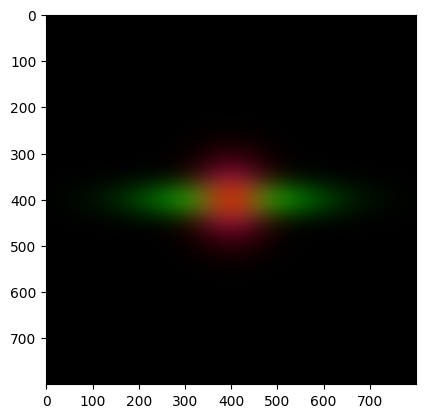

In [ ]:
means_3d = torch.tensor([
    [-0.00, 0.0, 0.01],

    [0.0, 0.0,  0.02],

    [0.0, 0.0,  0.04]
])

cov_3d = torch.tensor([
    [[0.2, 0.0, 0.0],
     [0.0, 0.2, 0.0],
     [0.0, 0.0, 0.2]],

    [[1.0, 0.0, 0.0],
     [0.0, 0.05, 0.0],
     [0.0, 0.0, 0.1]],

    [[0.1, 0.0, 0.0],
     [0.0, 0.1, 0.0],

     [0.0, 0.0, 0.1]]
])

opacities = torch.tensor([[0.7], [0.7], [0.7]])
colors = torch.tensor([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])

R = torch.eye(3)
T = torch.tensor([0.0, 0.0, -3.0])
camera = Camera(rotation=R, translation=T, width=800, height=800, fovy=0.26, fovx=0.26)

means_2d = camera.project_points(means_3d)
cov2d = covariance_from_3d_to_2d(camera, means_3d, cov_3d)
print(means_2d.shape)
print(cov2d.shape)
image = render_alpha_blend(800, 800, means_2d, cov2d, colors, opacities)

plt.imshow(image.permute(1, 2, 0).cpu().detach())
plt.show()

In [29]:
import imageio
from IPython.display import HTML
from base64 import b64encode

from torch import device

def array_to_video_html(array):
    imageio.mimwrite('temp.mp4', array, fps=30)
    video_encoded = b64encode(open('temp.mp4', 'rb').read()).decode()
    return f'<video controls><source src="data:video/mp4;base64,{video_encoded}" type="video/mp4"></video>'

def lookat_to_rt(eye, target, up):
    look_dir = target - eye
    look_dir = look_dir / look_dir.norm()
    right = torch.linalg.cross(up, look_dir)
    right = right / right.norm()
    up = torch.linalg.cross(right, look_dir)
    up = up / up.norm()

    tx = -torch.dot(right, eye)
    ty = -torch.dot(up, eye)
    tz = -torch.dot(look_dir, eye)

    rotation = torch.stack([right, up, look_dir], dim=1)
    translation = torch.tensor([tx, ty, tz])

    return rotation, translation

def create_cam_from_lookat(
    eye: torch.Tensor,
    target: torch.Tensor,
    up: torch.Tensor,
    width: int,
    height: int,
    fovy: float,
    fovx: float,
):
    rotation, translation = lookat_to_rt(eye, target, up)
    return Camera(rotation, translation, width, height, fovy, fovx)

def get_circular_trajectory_around_point(center_point, radius, width, height, fovx, fovy, up=torch.tensor([0.0, 1.0, 0.0]), num_cameras=150):
    theta = torch.linspace(0, 2 * math.pi, steps=num_cameras)
    x = radius * torch.sin(theta)
    y = torch.ones_like(theta) * 0.0
    z = -radius * torch.cos(theta)
    camera_positions = torch.stack([x, y, z], dim=1) + center_point
    look_at = center_point

    cameras = []
    for cam_position in camera_positions:
        cam = create_cam_from_lookat(cam_position, look_at, up, width, height, fovx, fovy)
        cameras.append(cam)
    return cameras

cameras = get_circular_trajectory_around_point(center_point=torch.tensor([0.0, 0.0, 0.0]), radius=10.0, width=800, height=800, fovx=0.26, fovy=0.26)

imgs = []
for cam in cameras:
    means_2d = cam.project_points(means_3d)
    cov2d = covariance_from_3d_to_2d(cam, means_3d, cov_3d)
    image = render_alpha_blend(800, 800, means_2d, cov2d, colors, opacities)
    imgs.append(image)

frame_list = (255 * torch.stack(imgs).permute(0, 2, 3, 1)).byte().cpu().numpy()
HTML(array_to_video_html(frame_list))

torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
torch.Size([1, 3, 3, 3])
